# Data Overview and Distribution


In [40]:
import json
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from collections import Counter


In [41]:
INPUT_JSONL = "../data/parsed_extracted_data.jsonl"

records = []
with open(INPUT_JSONL, "r", encoding="utf-8") as f:
    for line in f:
        records.append(json.loads(line))

df = pd.DataFrame(records)

print(f"Loaded {len(records)} records")
print(records[0].keys())


Loaded 165 records
dict_keys(['Done ?', 'Who?', 'ID', 'Title', 'Authors', 'Venue type', 'Venue', 'Year', 'Task', 'Automation level', 'Model', 'Learning type', 'Model category', 'Model subcategory', 'Training method', 'Input features', 'Pre-processing techniques', 'Encoding techniques', 'Output', 'Dataset availability', 'Dataset', 'Dataset size', 'Language', 'Evaluation type', 'Evaluation method', 'Metrics', 'Baseline', 'Replication package', 'Challenges', 'Remarks', 'Task_Categories'])


### Venues

In [42]:
venues = [r["Venue"] if r["Venue"] else r["Venue type"] for r in records]


In [43]:
venues[0:10]


['BDAS',
 'ICSME',
 'MSR',
 'ESEM',
 'IST',
 'SNPD',
 'ASE',
 'FedCSIS',
 'SEKE',
 'ISCO']

In [44]:
venues_df = pd.DataFrame(venues, columns=["Venue"])


In [45]:
venues_df.head()


,Venue
0,BDAS
1,ICSME
2,MSR
3,ESEM
4,IST


In [46]:
venue_counts = venues_df["Venue"].value_counts()


In [47]:
import pandas as pd

# EXPORT DATA FOR FLOURISH PARLIAMENT CHART
# Expected Flourish format:
# Column 1: Party (venue name)
# Column 2: Seats (count)

# df must already exist and contain a "Venue" column

# Keep venues with at least 2 papers, group the rest as "Other"
main = venue_counts[venue_counts >= 2]
other_count = venue_counts[venue_counts < 2].sum()

# Build Flourish-ready dataframe
flourish_df = main.reset_index()
flourish_df.columns = ["Party", "Seats"]

if other_count > 0:
    flourish_df = pd.concat(
        [flourish_df, pd.DataFrame([{"Party": "Other", "Seats": other_count}])],
        ignore_index=True,
    )

# Sort for nicer legend order (optional but recommended)
flourish_df = flourish_df.sort_values("Seats", ascending=False)

# Export to CSV (ready to upload to Flourish)
OUTPUT_CSV = "flourish_parliament_data.csv"
flourish_df.to_csv(OUTPUT_CSV, index=False)

print(f"✅ Flourish parliament data exported to: {OUTPUT_CSV}")
print(flourish_df)


✅ Flourish parliament data exported to: flourish_parliament_data.csv
                                         Party  Seats
22                                       Other     41
0                                        arXiv     29
1                                         ICSE     11
2                                          MSR      9
3                                          FSE      9
4                                          TSE      7
5                                         EMSE      7
6                                        SANER      7
7                                          IST      6
8                                          ASE      6
9                                         ESEM      4
10                                       TOSEM      4
13                                 IEEE Access      3
12                                       ICSME      3
11                                       ISSRE      3
14                                       APSEC      2
15           

In [48]:
len(venues)


165

In [49]:
svg = """
<svg id="chart-container" font-family="Canva Sans Variable" width="773" height="453.61502066826847"><g class="arc-container" transform="translate(386.5,369.9357142857143)"><g class="arc-bg"><circle class="outer" cx="0" cy="0" fill="#ffffff" r="370.9357142857143"></circle><circle class="inner" cx="0" cy="0" fill="#ffffff" r="139.0357142857143"></circle></g><g class="points-container"><g class="party-group" tabindex="0" data-party="Other" style="opacity: 1;"><circle fill="rgb(211, 211, 211)" stroke="#D3D3D3" class="circle" transform="translate(-152.25128173828125, 26.84600830078125)" r="15.564285714285713"></circle><circle fill="rgb(211, 211, 211)" stroke="#D3D3D3" class="circle" transform="translate(-184.87655639648438, 32.598724365234375)" r="15.564285714285713"></circle><circle fill="rgb(211, 211, 211)" stroke="#D3D3D3" class="circle" transform="translate(-217.5018310546875, 38.3514404296875)" r="15.564285714285713"></circle><circle fill="rgb(211, 211, 211)" stroke="#D3D3D3" class="circle" transform="translate(-250.12710571289062, 44.104156494140625)" r="15.564285714285713"></circle><circle fill="rgb(211, 211, 211)" stroke="#D3D3D3" class="circle" transform="translate(-282.75238037109375, 49.85687255859375)" r="15.564285714285713"></circle><circle fill="rgb(211, 211, 211)" stroke="#D3D3D3" class="circle" transform="translate(-315.3776550292969, 55.609588623046875)" r="15.564285714285713"></circle><circle fill="rgb(211, 211, 211)" stroke="#D3D3D3" class="circle" transform="translate(-348.0029296875, 61.3623046875)" r="15.564285714285713"></circle><circle fill="rgb(211, 211, 211)" stroke="#D3D3D3" class="circle" transform="translate(-352.6148376464844, 23.111597061157227)" r="15.564285714285713"></circle><circle fill="rgb(211, 211, 211)" stroke="#D3D3D3" class="circle" transform="translate(-319.773193359375, 17.33759880065918)" r="15.564285714285713"></circle><circle fill="rgb(211, 211, 211)" stroke="#D3D3D3" class="circle" transform="translate(-286.8814392089844, 11.56092643737793)" r="15.564285714285713"></circle><circle fill="rgb(211, 211, 211)" stroke="#D3D3D3" class="circle" transform="translate(-253.91990661621094, 5.781527042388916)" r="15.564285714285713"></circle><circle fill="rgb(211, 211, 211)" stroke="#D3D3D3" class="circle" transform="translate(-220.8478240966797, -2.0287528038024902)" r="15.564285714285713"></circle><circle fill="rgb(211, 211, 211)" stroke="#D3D3D3" class="circle" transform="translate(-187.54989624023438, -8.188605308532715)" r="15.564285714285713"></circle><circle fill="rgb(211, 211, 211)" stroke="#D3D3D3" class="circle" transform="translate(-353.03509521484375, -15.41384506225586)" r="15.564285714285713"></circle><circle fill="rgb(211, 211, 211)" stroke="#D3D3D3" class="circle" transform="translate(-319.5413513183594, -21.18528175354004)" r="15.564285714285713"></circle><circle fill="rgb(211, 211, 211)" stroke="#D3D3D3" class="circle" transform="translate(-153.91778564453125, -14.507817268371582)" r="15.564285714285713"></circle><circle fill="rgb(211, 211, 211)" stroke="#D3D3D3" class="circle" transform="translate(-285.8473205566406, -26.94308853149414)" r="15.564285714285713"></circle><circle fill="rgb(211, 211, 211)" stroke="#D3D3D3" class="circle" transform="translate(-251.87527465820312, -32.674015045166016)" r="15.564285714285713"></circle><circle fill="rgb(211, 211, 211)" stroke="#D3D3D3" class="circle" transform="translate(-349.25872802734375, -53.75605773925781)" r="15.564285714285713"></circle><circle fill="rgb(211, 211, 211)" stroke="#D3D3D3" class="circle" transform="translate(-314.6854553222656, -59.40159225463867)" r="15.564285714285713"></circle><circle fill="rgb(211, 211, 211)" stroke="#D3D3D3" class="circle" transform="translate(-216.7605743408203, -42.34066390991211)" r="15.564285714285713"></circle><circle fill="rgb(211, 211, 211)" stroke="#D3D3D3" class="circle" transform="translate(-279.6686096191406, -64.96218872070312)" r="15.564285714285713"></circle><circle fill="rgb(211, 211, 211)" stroke="#D3D3D3" class="circle" transform="translate(-181.33187866210938, -48.587730407714844)" r="15.564285714285713"></circle><circle fill="rgb(211, 211, 211)" stroke="#D3D3D3" class="circle" transform="translate(-341.3305969238281, -91.45925903320312)" r="15.564285714285713"></circle><circle fill="rgb(211, 211, 211)" stroke="#D3D3D3" class="circle" transform="translate(-244.0402069091797, -70.37840270996094)" r="15.564285714285713"></circle><circle fill="rgb(211, 211, 211)" stroke="#D3D3D3" class="circle" transform="translate(-305.27581787109375, -96.75830841064453)" r="15.564285714285713"></circle><circle fill="rgb(211, 211, 211)" stroke="#D3D3D3" class="circle" transform="translate(-144.5535125732422, -54.82191467285156)" r="15.564285714285713"></circle><circle fill="rgb(211, 211, 211)" stroke="#D3D3D3" class="circle" transform="translate(-268.4565124511719, -101.81212615966797)" r="15.564285714285713"></circle><circle fill="rgb(211, 211, 211)" stroke="#D3D3D3" class="circle" transform="translate(-329.3449401855469, -128.0752410888672)" r="15.564285714285713"></circle><circle fill="rgb(211, 211, 211)" stroke="#D3D3D3" class="circle" transform="translate(-205.3776397705078, -81.22747802734375)" r="15.564285714285713"></circle><circle fill="rgb(211, 211, 211)" stroke="#D3D3D3" class="circle" transform="translate(-291.44854736328125, -132.71485900878906)" r="15.564285714285713"></circle><circle fill="rgb(211, 211, 211)" stroke="#D3D3D3" class="circle" transform="translate(-230.59483337402344, -106.46485137939453)" r="15.564285714285713"></circle><circle fill="rgb(211, 211, 211)" stroke="#D3D3D3" class="circle" transform="translate(-166.51727294921875, -86.68341064453125)" r="15.564285714285713"></circle><circle fill="rgb(211, 211, 211)" stroke="#D3D3D3" class="circle" transform="translate(-313.44427490234375, -163.16876220703125)" r="15.564285714285713"></circle><circle fill="rgb(211, 211, 211)" stroke="#D3D3D3" class="circle" transform="translate(-252.41285705566406, -136.82968139648438)" r="15.564285714285713"></circle><circle fill="rgb(211, 211, 211)" stroke="#D3D3D3" class="circle" transform="translate(-273.4037780761719, -166.7509002685547)" r="15.564285714285713"></circle><circle fill="rgb(211, 211, 211)" stroke="#D3D3D3" class="circle" transform="translate(-187.08213806152344, -117.38035583496094)" r="15.564285714285713"></circle><circle fill="rgb(211, 211, 211)" stroke="#D3D3D3" class="circle" transform="translate(-211.8482666015625, -140.10374450683594)" r="15.564285714285713"></circle><circle fill="rgb(211, 211, 211)" stroke="#D3D3D3" class="circle" transform="translate(-293.8175964355469, -196.32264709472656)" r="15.564285714285713"></circle><circle fill="rgb(211, 211, 211)" stroke="#D3D3D3" class="circle" transform="translate(-124.82957458496094, -91.20710754394531)" r="15.564285714285713"></circle><circle fill="rgb(211, 211, 211)" stroke="#D3D3D3" class="circle" transform="translate(-231.82635498046875, -169.38462829589844)" r="15.564285714285713"></circle></g><g class="party-group" tabindex="0" data-party="arXiv" style="opacity: 1;"><circle fill="rgb(128, 128, 128)" stroke="rgb(128, 128, 128)" class="circle" transform="translate(-251.40261840820312, -198.37391662597656)" r="15.564285714285713"></circle><circle fill="rgb(128, 128, 128)" stroke="rgb(128, 128, 128)" class="circle" transform="translate(-143.8084259033203, -120.66960144042969)" r="15.564285714285713"></circle><circle fill="rgb(128, 128, 128)" stroke="rgb(128, 128, 128)" class="circle" transform="translate(-270.6982116699219, -227.1427764892578)" r="15.564285714285713"></circle><circle fill="rgb(128, 128, 128)" stroke="rgb(128, 128, 128)" class="circle" transform="translate(-188.2314453125, -170.52174377441406)" r="15.564285714285713"></circle><circle fill="rgb(128, 128, 128)" stroke="rgb(128, 128, 128)" class="circle" transform="translate(-162.48988342285156, -149.5824737548828)" r="15.564285714285713"></circle><circle fill="rgb(128, 128, 128)" stroke="rgb(128, 128, 128)" class="circle" transform="translate(-207.06752014160156, -198.89105224609375)" r="15.564285714285713"></circle><circle fill="rgb(128, 128, 128)" stroke="rgb(128, 128, 128)" class="circle" transform="translate(-225.76345825195312, -227.12628173828125)" r="15.564285714285713"></circle><circle fill="rgb(128, 128, 128)" stroke="rgb(128, 128, 128)" class="circle" transform="translate(-244.3609619140625, -255.26278686523438)" r="15.564285714285713"></circle><circle fill="rgb(128, 128, 128)" stroke="rgb(128, 128, 128)" class="circle" transform="translate(-160.28732299804688, -197.01959228515625)" r="15.564285714285713"></circle><circle fill="rgb(128, 128, 128)" stroke="rgb(128, 128, 128)" class="circle" transform="translate(-96.1595230102539, -121.05580139160156)" r="15.564285714285713"></circle><circle fill="rgb(128, 128, 128)" stroke="rgb(128, 128, 128)" class="circle" transform="translate(-178.58197021484375, -224.8179168701172)" r="15.564285714285713"></circle><circle fill="rgb(128, 128, 128)" stroke="rgb(128, 128, 128)" class="circle" transform="translate(-196.8572998046875, -252.59194946289062)" r="15.564285714285713"></circle><circle fill="rgb(128, 128, 128)" stroke="rgb(128, 128, 128)" class="circle" transform="translate(-114.28191375732422, -148.93508911132812)" r="15.564285714285713"></circle><circle fill="rgb(128, 128, 128)" stroke="rgb(128, 128, 128)" class="circle" transform="translate(-215.118896484375, -280.348388671875)" r="15.564285714285713"></circle><circle fill="rgb(128, 128, 128)" stroke="rgb(128, 128, 128)" class="circle" transform="translate(-132.42855834960938, -176.74996948242188)" r="15.564285714285713"></circle><circle fill="rgb(128, 128, 128)" stroke="rgb(128, 128, 128)" class="circle" transform="translate(-183.31964111328125, -302.1014404296875)" r="15.564285714285713"></circle><circle fill="rgb(128, 128, 128)" stroke="rgb(128, 128, 128)" class="circle" transform="translate(-165.10244750976562, -274.40240478515625)" r="15.564285714285713"></circle><circle fill="rgb(128, 128, 128)" stroke="rgb(128, 128, 128)" class="circle" transform="translate(-146.88235473632812, -246.69857788085938)" r="15.564285714285713"></circle><circle fill="rgb(128, 128, 128)" stroke="rgb(128, 128, 128)" class="circle" transform="translate(-128.65830993652344, -218.9880828857422)" r="15.564285714285713"></circle><circle fill="rgb(128, 128, 128)" stroke="rgb(128, 128, 128)" class="circle" transform="translate(-97.90999603271484, -197.9684600830078)" r="15.564285714285713"></circle><circle fill="rgb(128, 128, 128)" stroke="rgb(128, 128, 128)" class="circle" transform="translate(-79.3375244140625, -170.13986206054688)" r="15.564285714285713"></circle><circle fill="rgb(128, 128, 128)" stroke="rgb(128, 128, 128)" class="circle" transform="translate(-149.34121704101562, -320.2632751464844)" r="15.564285714285713"></circle><circle fill="rgb(128, 128, 128)" stroke="rgb(128, 128, 128)" class="circle" transform="translate(-130.9584197998047, -292.24200439453125)" r="15.564285714285713"></circle><circle fill="rgb(128, 128, 128)" stroke="rgb(128, 128, 128)" class="circle" transform="translate(-60.59803771972656, -142.22882080078125)" r="15.564285714285713"></circle><circle fill="rgb(128, 128, 128)" stroke="rgb(128, 128, 128)" class="circle" transform="translate(-112.53921508789062, -264.1392517089844)" r="15.564285714285713"></circle><circle fill="rgb(128, 128, 128)" stroke="rgb(128, 128, 128)" class="circle" transform="translate(-94.07154083251953, -235.92221069335938)" r="15.564285714285713"></circle><circle fill="rgb(128, 128, 128)" stroke="rgb(128, 128, 128)" class="circle" transform="translate(-113.5875244140625, -334.6180419921875)" r="15.564285714285713"></circle><circle fill="rgb(128, 128, 128)" stroke="rgb(128, 128, 128)" class="circle" transform="translate(-94.91930389404297, -305.85260009765625)" r="15.564285714285713"></circle><circle fill="rgb(128, 128, 128)" stroke="rgb(128, 128, 128)" class="circle" transform="translate(-60.09599304199219, -212.5237579345703)" r="15.564285714285713"></circle></g><g class="party-group" tabindex="0" data-party="ICSE" style="opacity: 1;"><circle fill="rgb(33, 151, 255)" stroke="rgb(33, 151, 255)" class="circle" transform="translate(-76.17062377929688, -276.8260192871094)" r="15.564285714285713"></circle><circle fill="rgb(33, 151, 255)" stroke="rgb(33, 151, 255)" class="circle" transform="translate(-57.3221321105957, -247.43264770507812)" r="15.564285714285713"></circle><circle fill="rgb(33, 151, 255)" stroke="rgb(33, 151, 255)" class="circle" transform="translate(-40.631900787353516, -183.27865600585938)" r="15.564285714285713"></circle><circle fill="rgb(33, 151, 255)" stroke="rgb(33, 151, 255)" class="circle" transform="translate(-76.48357391357422, -344.9951171875)" r="15.564285714285713"></circle><circle fill="rgb(33, 151, 255)" stroke="rgb(33, 151, 255)" class="circle" transform="translate(-57.506629943847656, -315.0372619628906)" r="15.564285714285713"></circle><circle fill="rgb(33, 151, 255)" stroke="rgb(33, 151, 255)" class="circle" transform="translate(-20.693695068359375, -153.2087860107422)" r="15.564285714285713"></circle><circle fill="rgb(33, 151, 255)" stroke="rgb(33, 151, 255)" class="circle" transform="translate(-38.431148529052734, -284.5306091308594)" r="15.564285714285713"></circle><circle fill="rgb(33, 151, 255)" stroke="rgb(33, 151, 255)" class="circle" transform="translate(-38.47044372558594, -351.2711181640625)" r="15.564285714285713"></circle><circle fill="rgb(33, 151, 255)" stroke="rgb(33, 151, 255)" class="circle" transform="translate(-20.259292602539062, -219.9259796142578)" r="15.564285714285713"></circle><circle fill="rgb(33, 151, 255)" stroke="rgb(33, 151, 255)" class="circle" transform="translate(-19.25493049621582, -253.25479125976562)" r="15.564285714285713"></circle><circle fill="rgb(33, 151, 255)" stroke="rgb(33, 151, 255)" class="circle" transform="translate(-19.261789321899414, -319.6630554199219)" r="15.564285714285713"></circle></g><g class="party-group" tabindex="0" data-party="MSR" style="opacity: 1;"><circle fill="rgb(242, 185, 15)" stroke="rgb(242, 185, 15)" class="circle" transform="translate(1.149505956323264e-14, -187.72857666015625)" r="15.564285714285713"></circle><circle fill="rgb(242, 185, 15)" stroke="rgb(242, 185, 15)" class="circle" transform="translate(1.758067873409725e-14, -287.1142883300781)" r="15.564285714285713"></circle><circle fill="rgb(242, 185, 15)" stroke="rgb(242, 185, 15)" class="circle" transform="translate(2.1637758181340325e-14, -353.3714294433594)" r="15.564285714285713"></circle><circle fill="rgb(242, 185, 15)" stroke="rgb(242, 185, 15)" class="circle" transform="translate(19.261789321899414, -319.6630554199219)" r="15.564285714285713"></circle><circle fill="rgb(242, 185, 15)" stroke="rgb(242, 185, 15)" class="circle" transform="translate(19.25493049621582, -253.25479125976562)" r="15.564285714285713"></circle><circle fill="rgb(242, 185, 15)" stroke="rgb(242, 185, 15)" class="circle" transform="translate(20.259292602539062, -219.9259796142578)" r="15.564285714285713"></circle><circle fill="rgb(242, 185, 15)" stroke="rgb(242, 185, 15)" class="circle" transform="translate(38.47044372558594, -351.2711181640625)" r="15.564285714285713"></circle><circle fill="rgb(242, 185, 15)" stroke="rgb(242, 185, 15)" class="circle" transform="translate(20.693695068359375, -153.2087860107422)" r="15.564285714285713"></circle><circle fill="rgb(242, 185, 15)" stroke="rgb(242, 185, 15)" class="circle" transform="translate(38.431148529052734, -284.5306091308594)" r="15.564285714285713"></circle></g><g class="party-group" tabindex="0" data-party="FSE" style="opacity: 1;"><circle fill="rgb(152, 82, 217)" stroke="rgb(152, 82, 217)" class="circle" transform="translate(57.506629943847656, -315.0372619628906)" r="15.564285714285713"></circle><circle fill="rgb(152, 82, 217)" stroke="rgb(152, 82, 217)" class="circle" transform="translate(40.631900787353516, -183.27865600585938)" r="15.564285714285713"></circle><circle fill="rgb(152, 82, 217)" stroke="rgb(152, 82, 217)" class="circle" transform="translate(76.48357391357422, -344.9951171875)" r="15.564285714285713"></circle><circle fill="rgb(152, 82, 217)" stroke="rgb(152, 82, 217)" class="circle" transform="translate(57.3221321105957, -247.43264770507812)" r="15.564285714285713"></circle><circle fill="rgb(152, 82, 217)" stroke="rgb(152, 82, 217)" class="circle" transform="translate(76.17062377929688, -276.8260192871094)" r="15.564285714285713"></circle><circle fill="rgb(152, 82, 217)" stroke="rgb(152, 82, 217)" class="circle" transform="translate(60.09599304199219, -212.5237579345703)" r="15.564285714285713"></circle><circle fill="rgb(152, 82, 217)" stroke="rgb(152, 82, 217)" class="circle" transform="translate(94.91930389404297, -305.85260009765625)" r="15.564285714285713"></circle><circle fill="rgb(152, 82, 217)" stroke="rgb(152, 82, 217)" class="circle" transform="translate(113.5875244140625, -334.6180419921875)" r="15.564285714285713"></circle><circle fill="rgb(152, 82, 217)" stroke="rgb(152, 82, 217)" class="circle" transform="translate(94.07154083251953, -235.92221069335938)" r="15.564285714285713"></circle></g><g class="party-group" tabindex="0" data-party="SANER" style="opacity: 1;"><circle fill="rgb(5, 136, 150)" stroke="rgb(5, 136, 150)" class="circle" transform="translate(60.59803771972656, -142.22882080078125)" r="15.564285714285713"></circle><circle fill="rgb(5, 136, 150)" stroke="rgb(5, 136, 150)" class="circle" transform="translate(112.53921508789062, -264.1392517089844)" r="15.564285714285713"></circle><circle fill="rgb(5, 136, 150)" stroke="rgb(5, 136, 150)" class="circle" transform="translate(130.9584197998047, -292.24200439453125)" r="15.564285714285713"></circle><circle fill="rgb(5, 136, 150)" stroke="rgb(5, 136, 150)" class="circle" transform="translate(79.3375244140625, -170.13986206054688)" r="15.564285714285713"></circle><circle fill="rgb(5, 136, 150)" stroke="rgb(5, 136, 150)" class="circle" transform="translate(149.34121704101562, -320.2632751464844)" r="15.564285714285713"></circle><circle fill="rgb(5, 136, 150)" stroke="rgb(5, 136, 150)" class="circle" transform="translate(97.90999603271484, -197.9684600830078)" r="15.564285714285713"></circle><circle fill="rgb(5, 136, 150)" stroke="rgb(5, 136, 150)" class="circle" transform="translate(128.65830993652344, -218.9880828857422)" r="15.564285714285713"></circle></g><g class="party-group" tabindex="0" data-party="TSE" style="opacity: 1;"><circle fill="rgb(250, 101, 2)" stroke="rgb(250, 101, 2)" class="circle" transform="translate(146.88235473632812, -246.69857788085938)" r="15.564285714285713"></circle><circle fill="rgb(250, 101, 2)" stroke="rgb(250, 101, 2)" class="circle" transform="translate(165.10244750976562, -274.40240478515625)" r="15.564285714285713"></circle><circle fill="rgb(250, 101, 2)" stroke="rgb(250, 101, 2)" class="circle" transform="translate(183.31964111328125, -302.1014404296875)" r="15.564285714285713"></circle><circle fill="rgb(250, 101, 2)" stroke="rgb(250, 101, 2)" class="circle" transform="translate(132.42855834960938, -176.74996948242188)" r="15.564285714285713"></circle><circle fill="rgb(250, 101, 2)" stroke="rgb(250, 101, 2)" class="circle" transform="translate(114.28191375732422, -148.93508911132812)" r="15.564285714285713"></circle><circle fill="rgb(250, 101, 2)" stroke="rgb(250, 101, 2)" class="circle" transform="translate(215.118896484375, -280.348388671875)" r="15.564285714285713"></circle><circle fill="rgb(250, 101, 2)" stroke="rgb(250, 101, 2)" class="circle" transform="translate(196.8572998046875, -252.59194946289062)" r="15.564285714285713"></circle></g><g class="party-group" tabindex="0" data-party="EMSE" style="opacity: 1;"><circle fill="rgb(9, 170, 100)" stroke="rgb(9, 170, 100)" class="circle" transform="translate(96.1595230102539, -121.05580139160156)" r="15.564285714285713"></circle><circle fill="rgb(9, 170, 100)" stroke="rgb(9, 170, 100)" class="circle" transform="translate(178.58197021484375, -224.8179168701172)" r="15.564285714285713"></circle><circle fill="rgb(9, 170, 100)" stroke="rgb(9, 170, 100)" class="circle" transform="translate(160.28732299804688, -197.01959228515625)" r="15.564285714285713"></circle><circle fill="rgb(9, 170, 100)" stroke="rgb(9, 170, 100)" class="circle" transform="translate(244.3609619140625, -255.26278686523438)" r="15.564285714285713"></circle><circle fill="rgb(9, 170, 100)" stroke="rgb(9, 170, 100)" class="circle" transform="translate(225.76345825195312, -227.12628173828125)" r="15.564285714285713"></circle><circle fill="rgb(9, 170, 100)" stroke="rgb(9, 170, 100)" class="circle" transform="translate(207.06752014160156, -198.89105224609375)" r="15.564285714285713"></circle><circle fill="rgb(9, 170, 100)" stroke="rgb(9, 170, 100)" class="circle" transform="translate(162.48988342285156, -149.5824737548828)" r="15.564285714285713"></circle></g><g class="party-group" tabindex="0" data-party="ASE" style="opacity: 1;"><circle fill="rgb(222, 44, 53)" stroke="rgb(222, 44, 53)" class="circle" transform="translate(188.2314453125, -170.52174377441406)" r="15.564285714285713"></circle><circle fill="rgb(222, 44, 53)" stroke="rgb(222, 44, 53)" class="circle" transform="translate(143.8084259033203, -120.66960144042969)" r="15.564285714285713"></circle><circle fill="rgb(222, 44, 53)" stroke="rgb(222, 44, 53)" class="circle" transform="translate(270.6982116699219, -227.1427764892578)" r="15.564285714285713"></circle><circle fill="rgb(222, 44, 53)" stroke="rgb(222, 44, 53)" class="circle" transform="translate(251.40261840820312, -198.37391662597656)" r="15.564285714285713"></circle><circle fill="rgb(222, 44, 53)" stroke="rgb(222, 44, 53)" class="circle" transform="translate(124.82957458496094, -91.20710754394531)" r="15.564285714285713"></circle><circle fill="rgb(222, 44, 53)" stroke="rgb(222, 44, 53)" class="circle" transform="translate(231.82635498046875, -169.38462829589844)" r="15.564285714285713"></circle></g><g class="party-group" tabindex="0" data-party="IST" style="opacity: 1;"><circle fill="rgb(19, 90, 225)" stroke="rgb(19, 90, 225)" class="circle" transform="translate(293.8175964355469, -196.32264709472656)" r="15.564285714285713"></circle><circle fill="rgb(19, 90, 225)" stroke="rgb(19, 90, 225)" class="circle" transform="translate(211.8482666015625, -140.10374450683594)" r="15.564285714285713"></circle><circle fill="rgb(19, 90, 225)" stroke="rgb(19, 90, 225)" class="circle" transform="translate(187.08213806152344, -117.38035583496094)" r="15.564285714285713"></circle><circle fill="rgb(19, 90, 225)" stroke="rgb(19, 90, 225)" class="circle" transform="translate(273.4037780761719, -166.7509002685547)" r="15.564285714285713"></circle><circle fill="rgb(19, 90, 225)" stroke="rgb(19, 90, 225)" class="circle" transform="translate(252.41285705566406, -136.82968139648438)" r="15.564285714285713"></circle><circle fill="rgb(19, 90, 225)" stroke="rgb(19, 90, 225)" class="circle" transform="translate(166.51727294921875, -86.68341064453125)" r="15.564285714285713"></circle></g><g class="party-group" tabindex="0" data-party="ESEM" style="opacity: 1;"><circle fill="rgb(128, 128, 128)" stroke="rgb(128, 128, 128)" class="circle" transform="translate(313.44427490234375, -163.16876220703125)" r="15.564285714285713"></circle><circle fill="rgb(128, 128, 128)" stroke="rgb(128, 128, 128)" class="circle" transform="translate(230.59483337402344, -106.46485137939453)" r="15.564285714285713"></circle><circle fill="rgb(128, 128, 128)" stroke="rgb(128, 128, 128)" class="circle" transform="translate(291.44854736328125, -132.71485900878906)" r="15.564285714285713"></circle><circle fill="rgb(128, 128, 128)" stroke="rgb(128, 128, 128)" class="circle" transform="translate(205.3776397705078, -81.22747802734375)" r="15.564285714285713"></circle></g><g class="party-group" tabindex="0" data-party="TOSEM" style="opacity: 1;"><circle fill="rgb(227, 11, 93)" stroke="rgb(227, 11, 93)" class="circle" transform="translate(329.3449401855469, -128.0752410888672)" r="15.564285714285713"></circle><circle fill="rgb(227, 11, 93)" stroke="rgb(227, 11, 93)" class="circle" transform="translate(144.5535125732422, -54.82191467285156)" r="15.564285714285713"></circle><circle fill="rgb(227, 11, 93)" stroke="rgb(227, 11, 93)" class="circle" transform="translate(268.4565124511719, -101.81212615966797)" r="15.564285714285713"></circle><circle fill="rgb(227, 11, 93)" stroke="rgb(227, 11, 93)" class="circle" transform="translate(305.27581787109375, -96.75830841064453)" r="15.564285714285713"></circle></g><g class="party-group" tabindex="0" data-party="ISSRE" style="opacity: 1;"><circle fill="rgb(209, 98, 181)" stroke="rgb(209, 98, 181)" class="circle" transform="translate(244.0402069091797, -70.37840270996094)" r="15.564285714285713"></circle><circle fill="rgb(209, 98, 181)" stroke="rgb(209, 98, 181)" class="circle" transform="translate(181.33187866210938, -48.587730407714844)" r="15.564285714285713"></circle><circle fill="rgb(209, 98, 181)" stroke="rgb(209, 98, 181)" class="circle" transform="translate(341.3305969238281, -91.45925903320312)" r="15.564285714285713"></circle></g><g class="party-group" tabindex="0" data-party="IEEE Access" style="opacity: 1;"><circle fill="rgb(0, 163, 169)" stroke="rgb(0, 163, 169)" class="circle" transform="translate(279.6686096191406, -64.96218872070312)" r="15.564285714285713"></circle><circle fill="rgb(0, 163, 169)" stroke="rgb(0, 163, 169)" class="circle" transform="translate(216.7605743408203, -42.34066390991211)" r="15.564285714285713"></circle><circle fill="rgb(0, 163, 169)" stroke="rgb(0, 163, 169)" class="circle" transform="translate(314.6854553222656, -59.40159225463867)" r="15.564285714285713"></circle></g><g class="party-group" tabindex="0" data-party="ICSME" style="opacity: 1;"><circle fill="rgb(197, 119, 50)" stroke="rgb(197, 119, 50)" class="circle" transform="translate(349.25872802734375, -53.75605773925781)" r="15.564285714285713"></circle><circle fill="rgb(197, 119, 50)" stroke="rgb(197, 119, 50)" class="circle" transform="translate(251.87527465820312, -32.674015045166016)" r="15.564285714285713"></circle><circle fill="rgb(197, 119, 50)" stroke="rgb(197, 119, 50)" class="circle" transform="translate(153.91778564453125, -14.507817268371582)" r="15.564285714285713"></circle></g><g class="party-group" tabindex="0" data-party="SPSC" style="opacity: 1;"><circle fill="rgb(110, 134, 237)" stroke="rgb(110, 134, 237)" class="circle" transform="translate(285.8473205566406, -26.94308853149414)" r="15.564285714285713"></circle><circle fill="rgb(110, 134, 237)" stroke="rgb(110, 134, 237)" class="circle" transform="translate(319.5413513183594, -21.18528175354004)" r="15.564285714285713"></circle></g><g class="party-group" tabindex="0" data-party="SCAM" style="opacity: 1;"><circle fill="rgb(40, 159, 79)" stroke="rgb(40, 159, 79)" class="circle" transform="translate(187.54989624023438, -8.188605308532715)" r="15.564285714285713"></circle><circle fill="rgb(40, 159, 79)" stroke="rgb(40, 159, 79)" class="circle" transform="translate(353.03509521484375, -15.41384506225586)" r="15.564285714285713"></circle></g><g class="party-group" tabindex="0" data-party="QRS" style="opacity: 1;"><circle fill="rgb(227, 91, 127)" stroke="rgb(227, 91, 127)" class="circle" transform="translate(220.8478240966797, -2.0287528038024902)" r="15.564285714285713"></circle><circle fill="rgb(227, 91, 127)" stroke="rgb(227, 91, 127)" class="circle" transform="translate(253.91990661621094, 5.781527042388916)" r="15.564285714285713"></circle></g><g class="party-group" tabindex="0" data-party="APSEC" style="opacity: 1;"><circle fill="rgb(0, 158, 216)" stroke="rgb(0, 158, 216)" class="circle" transform="translate(286.8814392089844, 11.56092643737793)" r="15.564285714285713"></circle><circle fill="rgb(0, 158, 216)" stroke="rgb(0, 158, 216)" class="circle" transform="translate(319.773193359375, 17.33759880065918)" r="15.564285714285713"></circle></g><g class="party-group" tabindex="0" data-party="SEKE" style="opacity: 1;"><circle fill="rgb(153, 139, 24)" stroke="rgb(153, 139, 24)" class="circle" transform="translate(352.6148376464844, 23.111597061157227)" r="15.564285714285713"></circle><circle fill="rgb(153, 139, 24)" stroke="rgb(153, 139, 24)" class="circle" transform="translate(152.25128173828125, 26.84600830078125)" r="15.564285714285713"></circle></g><g class="party-group" tabindex="0" data-party="JSS" style="opacity: 1;"><circle fill="rgb(182, 112, 209)" stroke="rgb(182, 112, 209)" class="circle" transform="translate(184.87655639648438, 32.598724365234375)" r="15.564285714285713"></circle><circle fill="rgb(182, 112, 209)" stroke="rgb(182, 112, 209)" class="circle" transform="translate(217.5018310546875, 38.3514404296875)" r="15.564285714285713"></circle></g><g class="party-group" tabindex="0" data-party="EASE" style="opacity: 1;"><circle fill="rgb(0, 163, 134)" stroke="rgb(0, 163, 134)" class="circle" transform="translate(250.12710571289062, 44.104156494140625)" r="15.564285714285713"></circle><circle fill="rgb(0, 163, 134)" stroke="rgb(0, 163, 134)" class="circle" transform="translate(282.75238037109375, 49.85687255859375)" r="15.564285714285713"></circle></g><g class="party-group" tabindex="0" data-party="ICPC" style="opacity: 1;"><circle fill="rgb(216, 105, 76)" stroke="rgb(216, 105, 76)" class="circle" transform="translate(315.3776550292969, 55.609588623046875)" r="15.564285714285713"></circle><circle fill="rgb(216, 105, 76)" stroke="rgb(216, 105, 76)" class="circle" transform="translate(348.0029296875, 61.3623046875)" r="15.564285714285713"></circle></g></g><g class="label-container" mask="url(#label-clip)" style="pointer-events: none;"><text class="party_count" dy="-0.05em" style="font-size: 16vw; font-weight: bold; text-anchor: middle; display: block; opacity: 0; fill: grey; transform: scale(1);"></text><text class="party_name" y="0" dy="1em" style="font-size: 4vw; font-weight: normal; text-anchor: middle; display: block; opacity: 0; fill: grey; transform-box: fill-box; transform-origin: center center; transform: scale(1);"></text></g></g><defs><radialGradient id="label-gradient"><stop offset="0%" style="stop-color: rgb(255, 255, 255); stop-opacity: 1;"></stop><stop offset="80%" style="stop-color: rgb(255, 255, 255); stop-opacity: 1;"></stop><stop offset="90%" style="stop-color: rgb(255, 255, 255); stop-opacity: 0.1;"></stop><stop offset="100%" style="stop-color: rgb(255, 255, 255); stop-opacity: 0;"></stop></radialGradient><mask id="label-clip"><circle fill="url(#label-gradient)" r="139.0357142857143"></circle></mask></defs></svg>
"""


In [50]:
with open("parliament.svg", "w", encoding="utf-8") as f:
    f.write(svg)

print("Saved as parliament.svg")


Saved as parliament.svg


In [51]:
import xml.etree.ElementTree as ET
import math

# 1. YOUR SVG CONTENT
svg_content = """
<svg id="chart-container" font-family="Canva Sans Variable" width="779.00390625" height="457.13825748286627" xmlns="http://www.w3.org/2000/svg">
    <g class="arc-container" transform="translate(389.501953125,370.2899553370134)">
        <g class="arc-bg">
            <circle class="outer" cx="0" cy="0" fill="#ffffff" r="371.2899553370134"></circle>
            <circle class="inner" cx="0" cy="0" fill="#ffffff" r="137.58878346201342"></circle>
        </g>
        <g class="points-container">
            </g>
    </g>
</svg>
"""

# Since the SVG you provided is very long, I will use a logic to PARSE the data you pasted
# and generate the legend specific to that data structure.
# You can simply paste your full SVG string into a file named 'input_chart.svg'
# and run the script below.


def create_legend_for_svg(input_filename, output_filename):
    ET.register_namespace("", "http://www.w3.org/2000/svg")

    # Load the SVG
    try:
        tree = ET.parse(input_filename)
        root = tree.getroot()
    except FileNotFoundError:
        # If file not found, we will create a dummy XML for demonstration using the snippet logic
        # But in your case, please save your SVG text to 'input_chart.svg'
        print("Please save your SVG code to a file named 'input_chart.svg' first.")
        return

    # namespace map usually needed for SVG parsing
    ns = {"svg": "http://www.w3.org/2000/svg"}
    # If the user's SVG doesn't have the xmlns link, ET might not need the namespace prefix,
    # but standards compliant SVGs usually do. We will try to handle both.

    # Find all party groups
    # We look for groups that have 'data-party' attribute
    party_groups = []

    # Helper to find elements with specific attributes (xpath doesn't support arbitrary attribs easily in stdlib)
    for group in root.iter():
        if "data-party" in group.attrib:
            party = group.attrib["data-party"]
            # Find the first circle child to get the fill color
            color = "#000000"  # default
            for circle in group:
                if "fill" in circle.attrib:
                    color = circle.attrib["fill"]
                    break
            party_groups.append({"name": party, "color": color})

    # Remove duplicates if any, preserving order
    unique_parties = []
    seen = set()
    for p in party_groups:
        if p["name"] not in seen:
            unique_parties.append(p)
            seen.add(p["name"])

    legend_x = 50
    legend_y = float(root.attrib.get("height", 457)) + 50  # Start below the chart
    col_width = 150
    row_height = 30
    font_size = 20
    cols = 5  # Number of columns

    # Calculate new height required
    num_items = len(unique_parties)
    items_per_col = math.ceil(num_items / cols)
    legend_height = items_per_col * row_height + 40

    # Update SVG height
    original_height = float(root.attrib.get("height", 457))
    new_height = original_height + legend_height
    root.attrib["height"] = str(new_height)

    # Create Legend Group
    legend_g = ET.SubElement(
        root,
        "g",
        attrib={
            "class": "legend",
            "transform": f"translate({legend_x}, {legend_y})",
            "font-family": root.attrib.get("font_family", "Arial, sans-serif"),
            "font-size": str(font_size),
        },
    )

    # Draw Legend Items
    for i, item in enumerate(unique_parties):
        col = i // items_per_col
        row = i % items_per_col

        x_pos = col * col_width
        y_pos = row * row_height

        # 1. Color Dot
        ET.SubElement(
            legend_g,
            "circle",
            attrib={
                "cx": str(x_pos),
                "cy": str(y_pos - 5),  # Offset to align with text
                "r": "6",
                "fill": item["color"],
            },
        )

        # 2. Text Label
        text = ET.SubElement(
            legend_g,
            "text",
            attrib={
                "x": str(x_pos + 15),
                "y": str(y_pos),
                "fill": "#333333",  # Dark gray text
                "dominant-baseline": "middle",
            },
        )
        text.text = item["name"]

    # Save output
    tree.write(output_filename)
    print(f"Success! Saved new SVG to {output_filename}")


# 1. Save your SVG text into a file named 'input_chart.svg'
# 2. Run this script
# 3. Open 'output_chart_with_legend.svg'
create_legend_for_svg("parliament.svg", "parliament_wlegend.svg")


Success! Saved new SVG to parliament_wlegend.svg


### Distribution of papers over venue types

In [52]:
df.columns


Index(['Done ?', 'Who?', 'ID', 'Title', 'Authors', 'Venue type', 'Venue',
       'Year', 'Task', 'Automation level', 'Model', 'Learning type',
       'Model category', 'Model subcategory', 'Training method',
       'Input features', 'Pre-processing techniques', 'Encoding techniques',
       'Output', 'Dataset availability', 'Dataset', 'Dataset size', 'Language',
       'Evaluation type', 'Evaluation method', 'Metrics', 'Baseline',
       'Replication package', 'Challenges', 'Remarks', 'Task_Categories'],
      dtype='object')

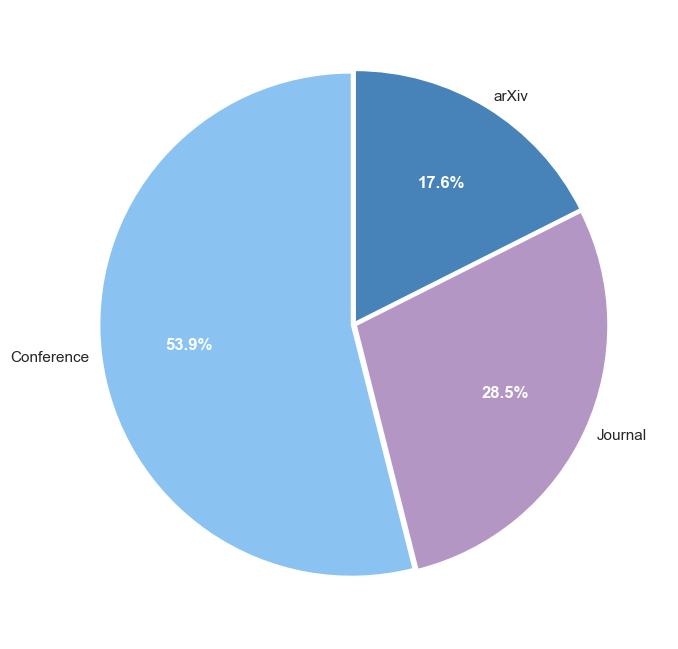

In [53]:
sns.set_theme(style="white")

custom_palette = {
    "Conference": "#8ac2f1",
    "Journal": "#b496c4",
    "arXiv": "#4782b9",
}

venue_type_counts = df["Venue type"].value_counts()
explode = [0.01] * len(venue_type_counts)

colors = [custom_palette[label] for label in venue_type_counts.index]

plt.figure(figsize=(7, 7))
wedges, texts, autotexts = plt.pie(
    venue_type_counts.values,
    labels=venue_type_counts.index,
    colors=colors,
    autopct="%1.1f%%",
    startangle=90,
    explode=explode,
    pctdistance=0.65,
    labeldistance=1.05,
    wedgeprops={"edgecolor": "white"},
)

for t in autotexts:
    t.set_color("white")
    t.set_fontweight("bold")
    t.set_fontsize(12)

plt.tight_layout()
plt.savefig("venue_types_dist.pdf", dpi=300, bbox_inches="tight")
plt.show()


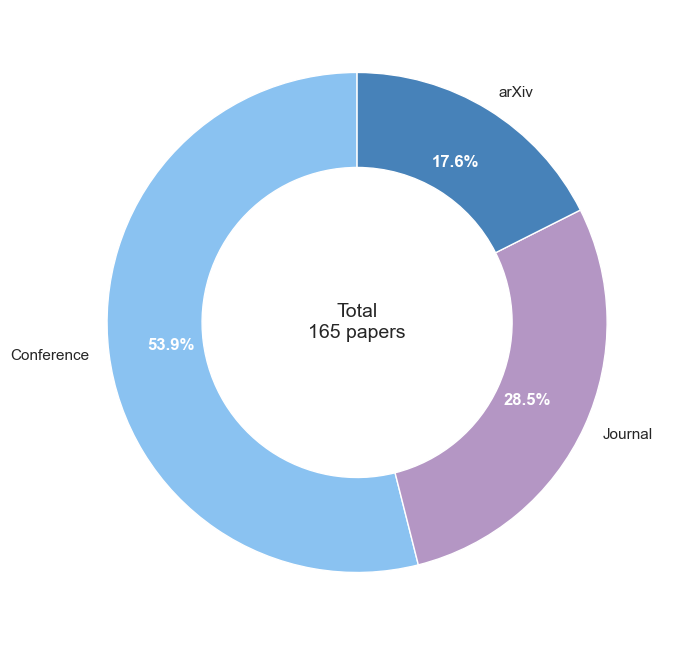

In [54]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="white")

custom_palette = {
    "Conference": "#8ac2f1",
    "Journal": "#b496c4",
    "arXiv": "#4782b9",
}

# DATA
venue_type_counts = df["Venue type"].value_counts()
total_papers = venue_type_counts.sum()

explode = [0] * len(venue_type_counts)
colors = [custom_palette[label] for label in venue_type_counts.index]

# DONUT (PIE) CHART
plt.figure(figsize=(7, 7))

wedges, texts, autotexts = plt.pie(
    venue_type_counts.values,
    labels=venue_type_counts.index,
    colors=colors,
    autopct="%1.1f%%",
    startangle=90,
    explode=explode,
    pctdistance=0.75,  # percentages slightly outward
    labeldistance=1.08,
    wedgeprops=dict(width=0.38, edgecolor="white"),  # 👈 makes it a donut
)

# Percentage text styling
for t in autotexts:
    t.set_color("white")
    t.set_fontweight("bold")
    t.set_fontsize(12)

# CENTER TEXT (TOTAL)
plt.text(
    0,
    0,
    f"Total\n{total_papers} papers",
    ha="center",
    va="center",
    fontsize=14,
)

plt.tight_layout()
plt.savefig("venue_types_dist.pdf", dpi=300, bbox_inches="tight")
plt.show()


### Distribution of paper over the years

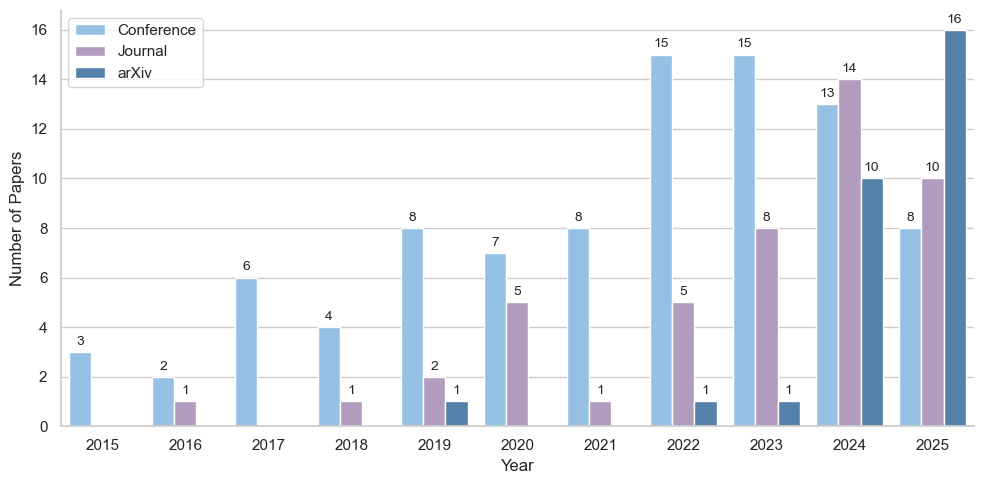

In [55]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")

custom_palette = {
    "Conference": "#8ac2f1",
    "Journal": "#b496c4",
    "arXiv": "#4782b9",
}

yearly_counts = df.groupby(["Year", "Venue type"]).size().reset_index(name="Count")

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=yearly_counts, x="Year", y="Count", hue="Venue type", palette=custom_palette
)

ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel("Number of Papers", fontsize=12)

ax.legend(title=None, frameon=True)

# 🔹 ADD VALUE LABELS
for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3, fontsize=10)

sns.despine()
plt.tight_layout()
plt.savefig("paper_types_by_year.pdf", dpi=300, bbox_inches="tight")
plt.show()


### PSs table

In [56]:
import pandas as pd
import numpy as np
import re

# Helpers


def latex_escape(text):
    """Escape LaTeX special characters."""
    if pd.isna(text):
        return ""
    text = str(text)
    replacements = {
        "&": r"\&",
        "%": r"\%",
        "$": r"\$",
        "#": r"\#",
        "_": r"\_",
        "{": r"\{",
        "}": r"\}",
        "~": r"\textasciitilde{}",
        "^": r"\textasciicircum{}",
        "\\": r"\textbackslash{}",
    }
    for k, v in replacements.items():
        text = text.replace(k, v)
    return text


def repl_symbol(value):
    """Map replication package status to LaTeX symbol."""
    if pd.isna(value):
        return r"$\times$"
    v = str(value).lower().strip()
    if v == "available":
        return r"\checkmark"
    if v == "partially available":
        return r"$\sim$"
    return r"$\times$"


# Configuration

TASK_PLACEHOLDER = r"\textcolor{black}{\textbullet}"

# Sort + reindex papers

df_clean = df.copy()

# Keep only valid years
df_clean = df_clean[pd.notna(df_clean["Year"])]

# Sort by year, then title (natural reading order)
df_clean = df_clean.sort_values(
    by=["Year", "Title"], key=lambda x: x if x.name != "Title" else x.str.lower()
).reset_index(drop=True)

# Reindex IDs as P1, P2, ...
df_clean["NewID"] = [f"P{i+1}" for i in range(len(df_clean))]

# Generate LaTeX

lines = []

# Header (you already include \begin{longtable} outside)
lines.append(r"\textbf{ID} & \textbf{Title} & \textbf{Task} & \textbf{Repl.} \\")
lines.append(r"\midrule")

current_year = None

for _, row in df_clean.iterrows():
    year = int(row["Year"])

    if year != current_year:
        if current_year is not None:
            lines.append("")  # spacing
        lines.append(rf"\midrule\multicolumn{{4}}{{c}}{{\textbf{{{year}}}}} \\")
        lines.append(r"\midrule")
        current_year = year

    pid = row["NewID"]
    title = latex_escape(row["Title"])
    task = TASK_PLACEHOLDER
    repl = repl_symbol(row["Replication package"])

    lines.append(f"{pid} & {title} & {task} & {repl} \\\\")

# Output

latex_output = "\n".join(lines)

print(latex_output)


\textbf{ID} & \textbf{Title} & \textbf{Task} & \textbf{Repl.} \\
\midrule
\midrule\multicolumn{4}{c}{\textbf{2015}} \\
\midrule
P1 & Supporting Code Review by Automatic Detection of Potentially Buggy Changes & \textcolor{black}{\textbullet} & \checkmark \\
P2 & Who should review this change?: Putting text and file location analyses together for more accurate recommendations & \textcolor{black}{\textbullet} & $\times$ \\
P3 & Will they like this? evaluating code contributions with language models & \textcolor{black}{\textbullet} & $\times$ \\

\midrule\multicolumn{4}{c}{\textbf{2016}} \\
\midrule
P4 & Predicting Defectiveness of Software Patches & \textcolor{black}{\textbullet} & $\times$ \\
P5 & Reviewer recommendation for pull-requests in GitHub: What can we learn from code review and bug assignment? & \textcolor{black}{\textbullet} & $\times$ \\
P6 & Testing and Code Review Based Effort-Aware Bug Prediction Model & \textcolor{black}{\textbullet} & $\times$ \\

\midrule\multicolumn{4}

In [57]:
len(records)


165

In [58]:
print(records[-1]["Title"])


Too Noisy To Learn: Enhancing Data Quality for Code Review Comment Generation
